In [5]:

import math
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchdiffeq import odeint, odeint_adjoint
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"


In [6]:
class Cos(nn.Module):
   def __init__(self):
        super().__init__()

       

   def forward(self,t,z):
        x, y = z[...,0], z[...,1]
      
        dx = -2*(torch.cos(x)-torch.sin(x)) - (torch.cos(y)-torch.sin(y))
        dy = -2*(torch.cos(y)-torch.sin(y)) - (torch.cos(x) - torch.sin(x))
        return torch.stack([dx, dy], dim=-1)

In [9]:
def makeDataSet(n_traj=200, T=3.0, step=60, noise_std=0.02):
    gt=Cos().to(device)
    t=torch.linspace(0.0, T, step, device=device)

    x0 = 1.2*(2*torch.rand(n_traj)-1)
    y0 = 1.2*(2*torch.rand(n_traj)-1)
    z0=torch.stack([x0,y0], dim=-1)

    with torch.no_grad():
        z_traj= odeint(gt, z0, t, method = "dopri5")
        z_traj=z_traj.transpose(0,1).contiguous()
        if noise_std > 0:
             z_traj = z_traj + noise_std * torch.randn_like(z_traj)
    return z0, t, z_traj

In [10]:
z0_all, t_eval, Z_all = makeDataSet(n_traj=400, T=1.0, step=100, noise_std=0.01)
N=z0_all.size(0)
perm=torch.randperm(N)


train_idx=perm[: int(0.8*N)] #перемешанные индексы 
test_idx=perm[int(0.8*N):]

z0_train, z0_test = z0_all[train_idx], z0_all[test_idx]
Z_train, Z_test = Z_all[train_idx], Z_all[test_idx]

train_load = DataLoader(TensorDataset(z0_train, Z_train), batch_size=64, shuffle=True)
test_load = DataLoader(TensorDataset(z0_test, Z_test), batch_size=128, shuffle=False)



/home/ekaterina2002/ODES/.venv/lib/python3.10/site-packages/torchdiffeq/_impl/misc.py:306: UserWarning: t is not on the same device as y0. Coercing to y0.device.
  warnings.warn("t is not on the same device as y0. Coercing to y0.device.")


In [22]:
torch.save({
    "z0_all": z0_all.cpu(),
    "Z_all": Z_all.cpu(),
    "t_eval": t_eval.cpu(),
    "train_idx": train_idx.cpu(),
    "test_idx": test_idx.cpu()
}, "dataset.pt")


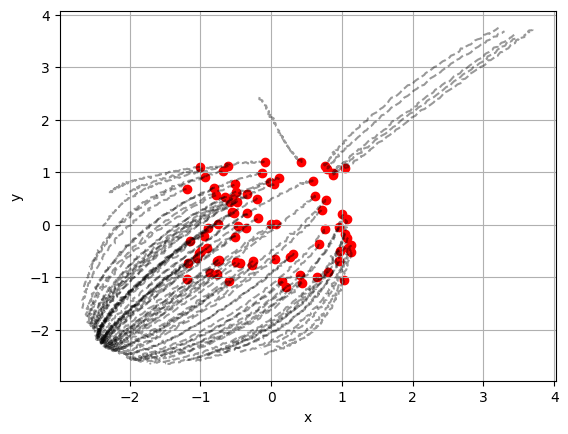

In [11]:


for z0_batch, Z_batch in test_load:
    for i in range (Z_batch.size(0)):
        x = Z_batch[i,:,0].cpu().numpy()
        y = Z_batch[i,:,1].cpu().numpy()
        plt.plot(x,y,'k--',alpha=0.4)

   
    plt.scatter(z0_batch[:, 0].cpu().numpy(),
                z0_batch[:, 1].cpu().numpy(),
                color='red')
    break

plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.show()
        

In [12]:
class ODEmodel(nn.Module):
    def __init__(self,state_dim=2, hidden=64, time_dependent=True):
        super().__init__()
        self.time_dependent = time_dependent

        in_dim = state_dim+(1 if time_dependent else 0)
        self.net=nn.Sequential(
            nn.Linear(in_dim, hidden),nn.Softplus(),
            nn.Linear(hidden, hidden), nn.Softplus(),
            nn.Linear(hidden,state_dim),
        )

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)
        

    def forward(self, t,z):
        if z.dim()==1:
            z = z.unsqueeze(0)
        if self.time_dependent:
            t_col = torch.full((z.size(0), 1), float(t), device=z.device, dtype=z.dtype)
            h = torch.cat([z, t_col], dim=-1)
        else:
            h = z
        return self.net(h)
    
class NeuralODE(nn.Module):
     def __init__(self, func, use_adjoint, rtol=1e-3, atol=1e-4, method="dopri5"):
            super().__init__()
            self.func = func
            self.use_adjoint = use_adjoint
            self.rtol = rtol
            self.atol = atol
            self.method = method


     def forward(self,z0,t):
            solver= odeint_adjoint if self.use_adjoint else odeint
            Z = solver(self.func, z0, t , rtol=self.rtol, atol=self.atol, method=self.method)
            return Z.transpose(0, 1).contiguous()



In [13]:
def mse ( z_hat, z_true):
    return torch.mean((z_hat-z_true)**2)

In [14]:
def evaluate(model, loader, t_eval):
    model.eval()
    mse_sum, count = 0.0, 0
    with torch.no_grad():
        for z0, Z in loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred=model(z0,t_eval)
            mse_sum += mse(Z_pred, Z).item()*z0.size(0)
            count +=z0.size(0)
        return mse_sum/count

In [20]:
def train(model, loader, t_eval, epochs=300, lr = 1e-2, clip_grad = 5.0, tag="NODE"):
    optim=  torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(1, epochs+1):
        model.train()
        for z0, Z in loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred=model(z0,t_eval)
            loss=mse(Z_pred, Z)

            optim.zero_grad()
            loss.backward()
            if clip_grad:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
            optim.step()
            
        if ep %12 ==0:
            tr = evaluate(model, train_load, t_eval)
            te = evaluate(model, test_load, t_eval)

            print(f"[{tag}] Epoch {ep:03d} | train {tr:.6f} | test {te:.6f}")
    
    return model




In [21]:


func_adj = ODEmodel().to(device)
node_adj = NeuralODE(func_adj, use_adjoint=True).to(device)

print("Training Neural ODE (adjoint only)...")
node_adj = train(node_adj, train_load, t_eval, tag="ADJ")

print("\n=== Final MSE ===")
print("Train:", evaluate(node_adj, train_load, t_eval))
print("Test :", evaluate(node_adj, test_load,  t_eval))



torch.save({
    "model_state": node_adj.state_dict(),
    "func_state": node_adj.func.state_dict(),  
}, "node_adj.pth")

Training Neural ODE (adjoint only)...


/tmp/ipykernel_4786/239119644.py:23: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  t_col = torch.full((z.size(0), 1), float(t), device=z.device, dtype=z.dtype)


[ADJ] Epoch 012 | train 0.419222 | test 0.536261
[ADJ] Epoch 024 | train 0.274559 | test 0.308626
[ADJ] Epoch 036 | train 0.094800 | test 0.102786
[ADJ] Epoch 048 | train 0.092474 | test 0.103932
[ADJ] Epoch 060 | train 0.083610 | test 0.083957
[ADJ] Epoch 072 | train 0.065676 | test 0.065345
[ADJ] Epoch 084 | train 0.016956 | test 0.016826
[ADJ] Epoch 096 | train 0.014378 | test 0.016687
[ADJ] Epoch 108 | train 0.014433 | test 0.017546
[ADJ] Epoch 120 | train 0.008424 | test 0.009437
[ADJ] Epoch 132 | train 0.006583 | test 0.006953
[ADJ] Epoch 144 | train 0.008925 | test 0.010164
[ADJ] Epoch 156 | train 0.008387 | test 0.005527
[ADJ] Epoch 168 | train 0.006497 | test 0.006534
[ADJ] Epoch 180 | train 0.003817 | test 0.004584
[ADJ] Epoch 192 | train 0.005830 | test 0.006509
[ADJ] Epoch 204 | train 0.015580 | test 0.011295
[ADJ] Epoch 216 | train 0.004066 | test 0.005107
[ADJ] Epoch 228 | train 0.003683 | test 0.004325
[ADJ] Epoch 240 | train 0.003311 | test 0.003815
[ADJ] Epoch 252 | tr

In [23]:
torch.save({
    "model_state": node_adj.state_dict(),
    "hidden": 64,
    "time_dependent": True,
    "use_adjoint": True
}, "model.pt")

In [17]:
func_adj = ODEmodel().to(device)   # те же параметры, что при обучении
node_adj = NeuralODE(func_adj, use_adjoint=True).to(device)

ckpt = torch.load("node_adj.pth", map_location=device)
node_adj.load_state_dict(ckpt["model_state"])

node_adj.eval()
func = node_adj.func

print("Model loaded")
print("Train MSE:", evaluate(node_adj, train_load, t_eval))
print("Test MSE :", evaluate(node_adj, test_load, t_eval))

Model loaded
Train MSE: 0.004134721960872412
Test MSE : 0.005286358296871185


In [24]:
func = node_adj.func

In [ ]:
import torch, numpy as np

def find_equilibrium(func, x0, t0=0.0, steps=2500, lr=0.02):
    x = x0.clone().detach().to(device).requires_grad_(True)
    opt = torch.optim.Adam([x], lr=lr)
    t0 = torch.tensor(float(t0), device=device)

    for _ in range(steps):
        v = func(t0, x.unsqueeze(0)).squeeze(0)   # (2,)
        loss = (v**2).sum()
        opt.zero_grad()
        loss.backward()
        opt.step()

    with torch.no_grad():
        res = torch.norm(func(t0, x.unsqueeze(0)).squeeze(0)).item()
    return x.detach(), res

t0 = 0.0
equilibria = []

for _ in range(80):
    x0 = (2*torch.rand(2, device=device)-1) * 2.0   

    if res < 1e-3:
        if all(torch.norm(p - x_star).item() > 1e-2 for p in equilibria):
            equilibria.append(x_star)

print("Found equilibria:", len(equilibria))
for i, p in enumerate(equilibria, 1):
    print(i, p.detach().cpu().numpy())

Found equilibria: 4
1 [0.7785265  0.77410215]
2 [-2.4117532  0.8121769]
3 [-2.3715618 -2.466326 ]
4 [ 0.68453985 -2.5792139 ]


In [26]:
torch.save(equilibria, "equilibria.pt")

In [ ]:


def jacobian_2d(func, x, t0=0.0):
   

    x = x.clone().detach().requires_grad_(True)
    t0 = torch.tensor(float(t0), device=x.device, dtype=x.dtype)

    
    y = func(t0, x.unsqueeze(0)).squeeze(0)

    J = torch.zeros(2, 2, device=x.device, dtype=x.dtype)

    for i in range(2):
        grad = torch.autograd.grad(y[i], x, retain_graph=True)[0]
        J[i] = grad

    return J

In [30]:


for i, x_star in enumerate(equilibria, 1):

    J = jacobian_2d(func, x_star, t0=0.0)
    eig = np.linalg.eigvals(J.detach().cpu().numpy())

    print(f"\n--- Equilibrium {i} ---")
    print("Eq* =", x_star.detach().cpu().numpy())
    print("Eigenvalues =", eig)

    if np.all(np.real(eig) < 0):
        print("Type: stable")
    elif np.all(np.real(eig) > 0):
        print("Type: unstable")
    elif np.real(eig[0]) * np.real(eig[1]) < 0:
        print("Type: saddle")
    else:
        print("Type: check manually")


--- Equilibrium 1 ---
Eq* = [0.7785265  0.77410215]
Eigenvalues = [1.3817996 4.243969 ]
Type: unstable

--- Equilibrium 2 ---
Eq* = [-2.4117532  0.8121769]
Eigenvalues = [-2.0942085  2.3614852]
Type: saddle

--- Equilibrium 3 ---
Eq* = [-2.3715618 -2.466326 ]
Eigenvalues = [-4.4698715 -1.4918954]
Type: stable

--- Equilibrium 4 ---
Eq* = [ 0.68453985 -2.5792139 ]
Eigenvalues = [ 2.3353605 -1.8917105]
Type: saddle


In [4]:
import os
print(os.listdir())

['GradientSystem.ipynb', 'node_adj.pth', 'GradientSystemEuler.ipynb', 'GradientSystemRK4.ipynb', 'SwitchingNeurons.ipynb', 'Cos.ipynb', 'RabbitsSheep.ipynb', 'H.ipynb']
